# Tổng Quan Dữ Liệu Thô

Dữ liệu thô là **dataset tổng hợp ~30,000 tựa game có mặt trên Steam**.

`01_overview.ipynb` sẽ cung cấp cái nhìn cơ bản về dữ liệu và các vấn đề( nếu có trên bộ dữ liệu) từ đó đưa ra giải pháp cho tiền xử lý giai đoạn 1( các xử lý chuyên sâu hơn sẽ được thực hiện ở các bước phân tích về sau), nó bao gồm:
- Xem thử vài mẫu dữ liệu trên dataset
- Phân tích các trường dữ liệu
- Kiểm thử mising value
- Kiểm tra tính unique của dữ liệu
- Đưa ra một vài thống kê đơn giản trên các trường dữ liệu

## Cài dặt các thư viện cần thiết

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

## Tải dữ liệu
Tải bộ dữ liệu lên bộ nhớ và xem thử vài dòng đầu của dữ liệu để có cái nhìn rõ hơn về dữ liệu thô từ đó có thể đi đến các bước kế tiếp trong quá trình khoa học dữ liệu.

In [2]:
df = pd.read_csv("../data/origin/SteamGames.csv")
df.head(5)

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,Description,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,OsRequirement,MemoryRequirement,CpuRequirement,Rank
0,3764200,Resident Evil Requiem,game,"Feb 26, 2026","Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",Resident Evil Requiem Deluxe Edition Resident ...,69.99$,https://shared.akamai.steamstatic.com/store_it...,NaN,9,23715,793,NaN,NaN,NaN,1
1,730,Counter-Strike 2,game,"Aug 21, 2012","Action,Free To Play",Valve,Valve,"For over two decades, Counter-Strike has offer...",0$,https://shared.akamai.steamstatic.com/store_it...,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393,Windows® 10,8 GB RAM,4 hardware CPU threads - Intel® Core™ i5 750 o...,2
2,1808500,ARC Raiders,game,"Oct 30, 2025",Action,Embark Studios,Embark Studios,ARC Raiders Deluxe Edition ARC Raiders Deluxe ...,39.99$,https://shared.akamai.steamstatic.com/store_it...,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194,Windows 10 or later 64-bit (latest update),12 GB RAM,Intel Core i5-6600K or AMD Ryzen R5 1600 proce...,3
3,359550,Tom Clancy's Rainbow Six Siege,game,"Dec 1, 2015","Action,Free To Play",Ubisoft Montreal,Ubisoft,Season 11 Year 1 Overview Year 11 Roadmap Free...,0$,https://shared.akamai.steamstatic.com/store_it...,NaN,8,522886,106839,NaN,NaN,NaN,4
4,1172470,Apex Legends™,game,"Nov 4, 2020","Action,Adventure,Free To Play",Respawn,Electronic Arts,Apex Legends: Breach About the Game Conquer wi...,0$,https://shared.akamai.steamstatic.com/store_it...,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216,64-bit Windows 10,6 GB RAM,"AMD FX 4350 or Equivalent, Intel Core i3 6300 ...",5


## Overview
### Các trường dữ liệu của dataset bao gồm

In [3]:
# Get features name 
features = df.columns.to_list()
features

['Appid',
 'Name',
 'Type',
 'ReleaseDate',
 'Genres',
 'Developers',
 'Publishers',
 'Description',
 'price',
 'Thumbnail',
 'Tags',
 'ReviewScore',
 'PositiveReview',
 'NegativeReview',
 'OsRequirement',
 'MemoryRequirement',
 'CpuRequirement',
 'Rank']

Đây là danh sách các trường dữ liệu và mô tả ngắn gọn của nó:
- **Appid:** Mã định danh duy nhất của trò chơi hoặc ứng dụng trên hệ thống Steam.

- **Name:** Tên chính thức của trò chơi.

- **Type:** Loại nội dung (ví dụ: game cơ bản, bản mở rộng DLC, phần mềm, v.v.).

- **ReleaseDate:** Ngày phát hành chính thức của trò chơi trên Steam.

- **Genres:** Các thể loại của trò chơi (ví dụ: Hành động, Nhập vai, Chiến thuật, v.v.).

- **Developers:** Tên (các) studio, cá nhân hoặc nhóm phát triển trò chơi.

- **Publishers:** Tên (các) công ty hoặc đơn vị chịu trách nhiệm phát hành trò chơi.

- **Description:** Đoạn văn bản tóm tắt nội dung, cốt truyện hoặc lối chơi của tựa game.

- **price:** Giá bán của trò chơi (thường được tính bằng USD hoặc nội tệ).

- **Thumbnail:** Đường dẫn (URL) đến hình ảnh thu nhỏ hoặc ảnh đại diện của trò chơi trên cửa hàng.

- **Tags:** Các thẻ từ khóa do cộng đồng người chơi gắn cho game (ví dụ: Multiplayer, Open World, v.v.).

- **ReviewScore:** Điểm số đánh giá tổng thể hoặc mức độ xếp hạng từ người chơi (ví dụ: Overwhelmingly Positive, Mixed).

- **PositiveReview:** Tổng số lượng bài đánh giá tích cực từ người chơi.

- **NegativeReview:** Tổng số lượng bài đánh giá tiêu cực từ người chơi.

- **OsRequirement:** Yêu cầu về hệ điều hành để có thể chạy được game (ví dụ: Windows 10, macOS, Linux).

- **MemoryRequirement:** Yêu cầu dung lượng bộ nhớ RAM tối thiểu hoặc đề nghị.

- **CpuRequirement:** Yêu cầu thông số vi xử lý (CPU) tối thiểu hoặc đề nghị.

- **Rank:** Thứ hạng của trò chơi trong tập dữ liệu (thường dựa trên doanh thu, số người chơi hoặc độ phổ biến).


### Kiểm Tra Missing Value Trên Từng Trường Dữ Liệu

In [4]:
n = df.shape[0]

print("Count for missing value:")
for feature in features:
    print(f"\t'{feature}': {df[feature].isnull().sum()}/{n}")

Count for missing value:
	'Appid': 0/29931
	'Name': 0/29931
	'Type': 0/29931
	'ReleaseDate': 14/29931
	'Genres': 413/29931
	'Developers': 26/29931
	'Publishers': 1045/29931
	'Description': 52/29931
	'price': 0/29931
	'Thumbnail': 0/29931
	'Tags': 1614/29931
	'ReviewScore': 0/29931
	'PositiveReview': 0/29931
	'NegativeReview': 0/29931
	'OsRequirement': 2937/29931
	'MemoryRequirement': 3984/29931
	'CpuRequirement': 3859/29931
	'Rank': 0/29931


*Nhóm Dữ liệu Hoàn hảo (0 dòng thiếu)*
- **Các trường:** Appid, Name, Type, price, Thumbnail, ReviewScore, PositiveReview, NegativeReview, Rank

- **Nhận định:** Đây là một tín hiệu cực kỳ xuất sắc. Các thông tin cốt lõi nhất của một tựa game bao gồm định danh (Appid, Name), tài chính (price), và thước đo chất lượng/độ phổ biến (ReviewScore, Reviews, Rank) đều đầy đủ 100%. Bạn có thể ngay lập tức thực hiện các phân tích về doanh thu, xếp hạng hoặc cảm xúc người dùng (sentiment analysis) mà không cần bước làm sạch phức tạp nào cho các cột này.

*Nhóm Thiếu hụt Không đáng kể (Dưới 1%)*
- **Các trường:** ReleaseDate (14), Developers (26), Description (52)

- **Nhận định:** Tỷ lệ thiếu hụt gần như bằng không (chỉ vài chục trên gần 30.000 dòng).
    + ReleaseDate thiếu có thể do các tựa game sắp ra mắt (TBA/TBD) hoặc chưa ấn định ngày.

    + Developers và Description thiếu có thể do lỗi nhỏ trong quá trình cào dữ liệu (crawl data) hoặc do trang của game trên Steam bị gỡ/thiếu thông tin.

- **Hướng xử lý:** Có thể tự tin xóa (drop) các dòng bị thiếu này mà không làm ảnh hưởng đến tính đại diện của toàn tập dữ liệu.

*Nhóm Thiếu hụt Nhẹ đến Trung bình (1% - 5.5%)*
- **Các trường:** Genres (413), Publishers (1045), Tags (1614)

- **Nhận định:**

    + Publishers (1045 thiếu - ~3.5%): Rất hợp lý vì nhiều tựa game độc lập (Indie games) tự phát triển và tự phát hành, do đó nhà phát triển thường để trống mục Publisher.

    + Tags (1614 thiếu - ~5.4%) và Genres (413 thiếu - ~1.4%): Trên Steam, "Tags" thường do cộng đồng người chơi gắn (community-driven). Các game quá mới, quá ít người chơi hoặc bị bỏ hoang thường sẽ không thu thập đủ lượt bình chọn để hiển thị Tag.

- **Hướng xử lý:** Thay vì xóa dòng, có thể điền (impute) các giá trị thiếu này bằng "Unknown", hoặc với trường Publishers, có thể copy dữ liệu từ cột Developers sang.

*Nhóm Thiếu hụt Đáng kể (10% - 13.5%)*
- **Các trường:** OsRequirement (2937), CpuRequirement (3859), MemoryRequirement (3984)

- **Nhận định:** Đây là nhóm có dữ liệu bị khuyết nhiều nhất. Nguyên nhân cốt lõi là do mục Cấu hình hệ thống (System Requirements) trên Steam không có một định dạng chuẩn bắt buộc. Các nhà phát triển thường gõ tay (free-text formatting), dẫn đến việc công cụ cào dữ liệu (scraper/parser) không thể bóc tách (extract) chính xác CPU, RAM hay OS. Ngoài ra, rất nhiều game cũ trên Steam không điền chi tiết cấu hình phần cứng.

- **Hướng xử lý:** Nếu bài toán của bạn không xoay quanh phần cứng, có thể bỏ qua các cột này. Nếu cần phân tích, có thể phải chấp nhận gom nhóm thành "Unknown" hoặc quay lại dùng NLP xử lý dữ liệu thô nếu file Kaggle có cung cấp cột raw requirements.

### Tổng Số Missing Value
Đếm tổng số dòng có ít nhất 1 trường có mising value. Như được thể hiện bên dưới, dữ liệu có khoảng **5536 dòng( khoảng 18.50\% bộ dữ liệu) có missing value**. Vì lượng dữ liệu có missing value là **đáng kể**, không thể đơn giản loại bỏ nó ra khỏi dataset vì nó có thể làm mất đặc trưng của dữ liệu, đặc biệt là khi **dữ liệu bị mất có thể là MNAR( Missing Not At Random)** hoặc **MAR( Mising At Random).**

In [5]:
df.isna().any(axis=1).sum()

np.int64(5536)

### Ma Trận Missing Value
Sử dụng ma trận Missing Value cho chúng ta cái nhìn cụ thể về vị trí cụ thể bị mất dữ liệu của từng trường. Trong các trường bị mất dữ liệu, chúng ta sẽ đi qua một số trường có nhiều giá trị bị mất nhất.

<Figure size 1000x600 with 0 Axes>

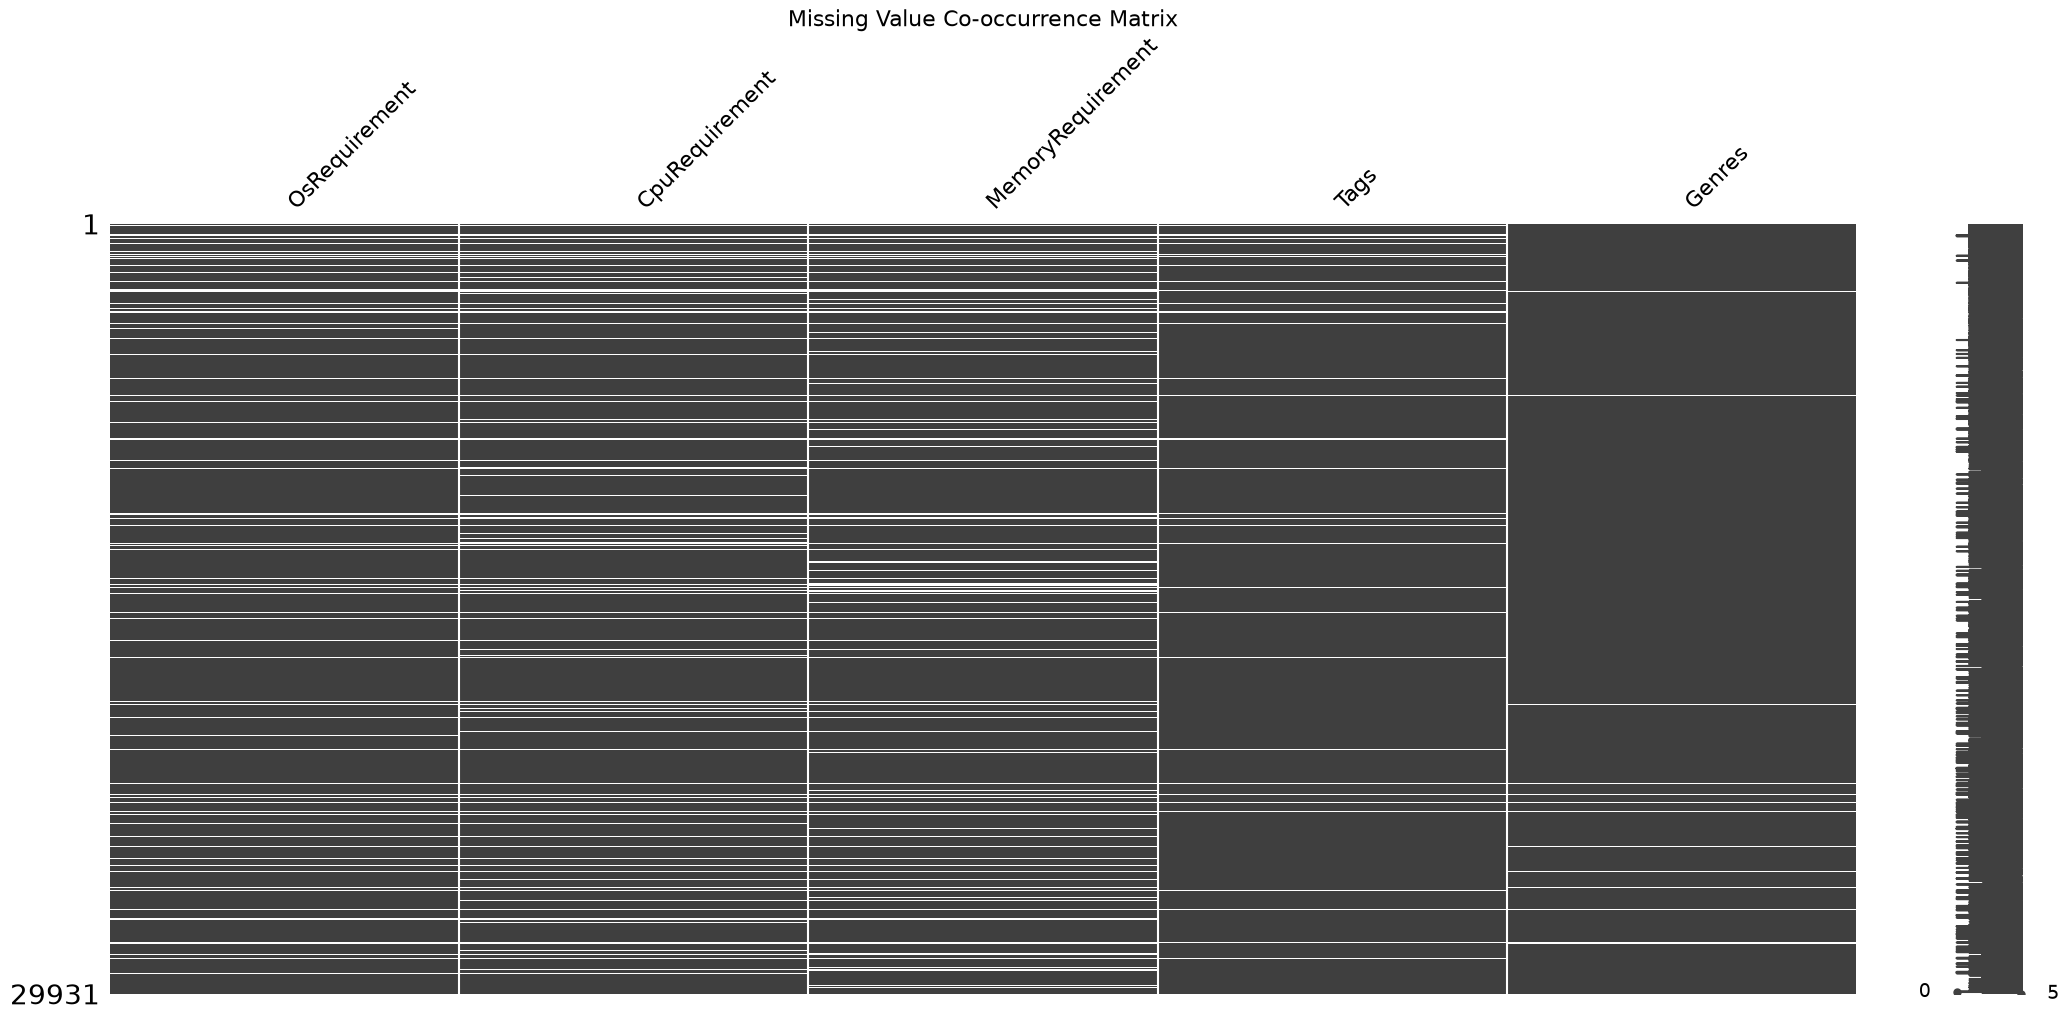

In [6]:
# Missing Value Matrix
# Visualizes the overlap of missingness across your target imputation features
plt.figure(figsize=(10, 6))
msno.matrix(df[['OsRequirement', 'CpuRequirement', 'MemoryRequirement', 'Tags', 'Genres']])
plt.title("Missing Value Co-occurrence Matrix", fontsize=16)
plt.show()

#### **Đọc hiểu ma trận (Missingno Matrix)**
- Màu sắc: Vùng màu xám đậm (hoặc đen) biểu thị dữ liệu hợp lệ (có giá trị). Vùng màu trắng (các đường ngang) biểu thị dữ liệu bị thiếu (missing value/NaN).

- Trục dọc: Thể hiện số lượng dòng, tương đương với tổng số tựa game trong dataset.   

- Trục ngang (Phía trên): Thể hiện 5 biến số có lượng missing value cao nhất: OsRequirement, CpuRequirement, MemoryRequirement, Tags, và Genres.   

- Biểu đồ tia bên phải (Sparkline): Hiển thị độ hoàn thiện của từng dòng. Dòng nào đụng mốc "5" nghĩa là dòng đó có đủ dữ liệu ở cả 5 cột này. Dòng nào thụt lùi về phía "0" nghĩa là dòng đó bị thiếu nhiều giá trị.   

#### Phân tích mức độ thiếu hụt của từng biến
Dựa vào mật độ các đường màu trắng, ta có thể sắp xếp mức độ thiếu hụt từ cao xuống thấp:
- Nhóm Yêu cầu cấu hình (MemoryRequirement, CpuRequirement, OsRequirement): Ba cột này có rất nhiều vạch trắng chằng chịt, kéo dài từ trên xuống dưới, cho thấy tỉ lệ thiếu dữ liệu ở nhóm này là cao nhất.   

- Tags: Có các vạch trắng xuất hiện nhưng thưa hơn nhiều so với nhóm cấu hình.   

- Genres: Cột này hầu như đặc đen, chỉ lác đác vài vạch trắng cực mỏng, cho thấy tỉ lệ thiếu hụt rất thấp.

#### **Phân tích Mối quan hệ đồng thời (Co-occurrence)**
Điểm giá trị nhất của biểu đồ này là giúp ta nhìn ra quy luật: khi một giá trị bị thiếu, nó có kéo theo các giá trị khác bị thiếu cùng lúc hay không?
- Sự tương quan cực mạnh trong nhóm cấu hình (Hardware Requirements):
    + 3 cột đầu tiên (OsRequirement, CpuRequirement, MemoryRequirement). Các đường màu trắng gần như chạy thẳng hàng ngang qua cả 3 cột.

    + Nhận định: Nếu một tựa game trên Steam không cung cấp thông tin về RAM (MemoryRequirement), thì gần như chắc chắn nó cũng sẽ không cung cấp thông tin về CPU (CpuRequirement) và hệ điều hành (OsRequirement), và ngược lại. Điều này rất hợp lý với thực tế: phần cấu hình (System Requirements) thường được nhà phát triển bỏ trống nguyên một cụm, chứ hiếm khi họ chỉ điền OS mà quên điền RAM.   
    
- Mối quan hệ giữa Tags và Genres:
    + Nếu nhìn kỹ vào những dòng bị thiếu Tags (vạch trắng ở cột Tags), bạn sẽ thấy một số (không phải tất cả) cũng chạy vắt ngang qua cột Genres.   
    
    + Nhận định: Những game thiếu Tags thường là những game thiếu thông tin định danh thể loại. Tuy nhiên, chiều ngược lại không hoàn toàn đúng. Rất nhiều game có Genres đầy đủ (màu đen) nhưng vẫn bị thiếu Tags (màu trắng). Điều này khẳng định lại bản chất: Genres do nhà phát triển khai báo (bắt buộc/phổ biến hơn), còn Tags phụ thuộc vào cộng đồng gắn thẻ (có thể bị bỏ trống nếu game ít người chơi).   
    
- Mối quan hệ giữa nhóm Cấu hình và nhóm Phân loại: 
    + Không có sự trùng khớp rõ rệt nào giữa các vạch trắng của nhóm Cấu hình với nhóm Tags/Genres.   
    + Nhận định: Việc một game thiếu cấu hình không liên quan đến việc nó có bị thiếu Tags hay Genres hay không. Hai nhóm missing value này xảy ra độc lập với nhau (Missing Completely at Random - MCAR giữa 2 nhóm).   

### Độ Đa Dạng Về Giá Trị Cho Từng Trường Dữ Liệu

In [7]:
print("Number of unique value per feature")
for feature in features:
    print(f'{feature}: {len(df[feature].unique())}')

Number of unique value per feature
Appid: 29789
Name: 29779
Type: 6
ReleaseDate: 4417
Genres: 1186
Developers: 14778
Publishers: 11239
Description: 29652
price: 452
Thumbnail: 29786
Tags: 24683
ReviewScore: 10
PositiveReview: 3980
NegativeReview: 1793
OsRequirement: 4028
MemoryRequirement: 400
CpuRequirement: 8431
Rank: 16719


Từ các giá trị thu được bên trên, ta có thể có một số kết luận:

#### **Dấu hiệu cảnh báo: Tập dữ liệu có chứa dòng lặp (Duplicates)**

Appid (29.789) và Name (29.779): Appid là mã định danh duy nhất, lẽ ra số unique phải bằng đúng tổng số dòng (29.931). Việc chỉ có 29.789 unique cho thấy có **khoảng hơn 140 dòng bị trùng lặp (duplicate rows) trong tập dữ liệu**. Ngoài ra, số lượng Name ít hơn Appid một chút cho thấy có một số tựa game trùng tên nhưng khác Appid (ví dụ: các bản Remaster, GOTY, hoặc phân vùng khác nhau).

**Hướng xử lý:** Việc đầu tiên cần làm là drop_duplicates() dựa trên Appid.


#### **Nhóm biến phân loại chuẩn (Categorical - Đã chuẩn hóa tốt)**

Type (6) và ReviewScore (10): Đây là hai trường có mức độ chuẩn hóa tuyệt vời.

Type (6 giá trị) thường xoay quanh: game, dlc, hardware, mod, v.v.

ReviewScore (10 giá trị) là các mốc đánh giá chuẩn của Steam như: Overwhelmingly Positive, Mostly Positive, Mixed, v.v.


#### **Nhóm dữ liệu kết hợp / Danh sách (Cần bóc tách)**

Genres (1.186) và Tags (24.683): Con số này cực kỳ lớn không phải vì Steam có hàng ngàn thể loại, mà vì đây là dữ liệu dạng chuỗi kết hợp (Ví dụ: "Action, Adventure, RPG" được tính là 1 giá trị duy nhất, khác với "Action, RPG, Adventure"). Gần như mỗi tựa game có một tổ hợp Tags riêng biệt.

**Hướng xử lý:** Không thể để nguyên cột này để phân tích. Cần dùng kỹ thuật tách chuỗi (Split) và mã hóa (One-hot encoding / Multi-label Binarizer) để tách thành các cột thể loại độc lập (Action: 1/0, RPG: 1/0...).

#### **Nhóm phần cứng ( chưa chuẩn hóa)**

CpuRequirement (8.431), OsRequirement (4.028), MemoryRequirement (400):

Đây chính là minh chứng rõ nhất cho lưu ý "nhiều giá trị phản ánh cùng một đối tượng". Các nhà phát triển nhập dữ liệu này dưới dạng văn bản tự do (free-text).

Ví dụ: "Windows 10", "Win 10", "Windows 10 64-bit", "Windows 7/8/10" đều bị tính là các giá trị khác nhau. Hoặc RAM ghi "4 GB", "4GB", "4096 MB" cũng bị đếm riêng.

**Hướng xử lý:** Cần dùng Regex (Biểu thức chính quy) để quét và trích xuất từ khóa. Ví dụ: quét chữ "Win 10" hoặc "Windows 10" gán thành 1 nhóm; quét các con số đi kèm "GB" trong cột Memory để chuyển về định dạng số nguyên (integer).


#### **Nhóm văn bản tự do / Ngày tháng**

ReleaseDate (4.417): Steam có nhiều định dạng ngày ("Oct 12, 2020", "October 2020", "Coming Soon", "TBA"). Việc chưa chuẩn hóa định dạng datetime khiến số lượng unique bị phình to. Cần ép kiểu về định dạng YYYY-MM-DD.

Developers (14.778) và Publishers (11.239): Mức độ phong phú này khá hợp lý vì Steam có vô số studio độc lập. Tuy nhiên, chắc chắn có sự trùng lặp do cách ghi (VD: "Valve", "Valve Corporation", "Valve Co."). Cần chuẩn hóa bằng cách chuyển về chữ thường (lowercase) và xóa các hậu tố công ty (Corp, LLC, Studio).

Description (29.652): Hầu hết các game đều có mô tả riêng, số lượng unique xấp xỉ số game là hoàn toàn bình thường.

#### **Nhóm biến số lượng / Định lượng (Numeric)**

price (452): Con số này hơi cao nếu chỉ là giá tiền chuẩn (thường dao động ở các mốc $9.99, $19.99...). Có thể cột này đang lưu dưới dạng text (chứa ký hiệu $ hoặc chữ "Free to Play"). Cần làm sạch ký tự và chuyển về kiểu float.

Rank (16.719), PositiveReview (3.980), NegativeReview (1.793): Các con số phân bổ này hoàn toàn bình thường đối với dữ liệu dạng số nguyên liên tục (continuous integer). Việc có 16.719 Rank thay vì ~29.000 cho thấy có rất nhiều tựa game bị đồng hạng (cùng mức xếp hạng).

## Biểu Đồ Cho Một Số Trường
### Các Loại Sản Phẩm Và Số Trường Của Chúng

In [8]:
game_type_set = df['Type'].unique()
counts = df['Type'].value_counts()
counts

Type
game        22713
dlc          6586
music         600
mod            26
hardware        5
video           1
Name: count, dtype: int64

- Thể loại "game" chiếm đa số (~75.9%): Với 22.713 dòng, "game" (trò chơi gốc) chiếm đại đa số. Điều này phản ánh chính xác bản chất cốt lõi của Steam là một nền tảng phân phối trò chơi.

- Xu hướng kinh doanh "dlc" (~22.0%): Với 6.586 dòng, DLC (Nội dung tải thêm/Bản mở rộng) chiếm một phần năm tập dữ liệu. Con số này cho thấy chiến lược kinh doanh cực kỳ phổ biến của ngành công nghiệp game: vòng đời của một tựa game được kéo dài để liên tục tạo ra doanh thu thông qua các gói nội dung bổ sung.

- Sản phẩm phụ trợ - "music" (~2.0%): 600 dòng này chủ yếu là các bản nhạc nền (Original Soundtracks - OST) được bán kèm theo game nhằm phục vụ cộng đồng người hâm mộ.

- Nhóm thiểu số "mod", "hardware", "video" (Rất hiếm): Số lượng không đáng kể (tổng cộng chỉ khoảng 30 mẫu). Steam từng bán/cho thuê video (phim, phim tài liệu về game), và có bán phần cứng (Steam Controller, Valve Index, Steam Deck), nhưng rõ ràng tập dữ liệu này không tập trung vào mảng đó.

### Phân Bố Giá Của Steam Game

--- 1. DATASET ARCHITECTURE & COMPOSITION ---
Total records: 29931

Breakdown by Application Type:
Type
game        22713
dlc          6586
music         600
mod            26
hardware        5
video           1
Name: count, dtype: int64

--- 2. CARDINALITY & DEDUPLICATION RISKS ---
Unique Appids: 29789 (Potential Duplicates: 142)
Unique Names: 29779 (Potential Duplicates: 152)
Unique Developers: 14777
Unique Publishers: 11238
Standardized Unique Tags: 446

--- 3. DATA QUALITY & MISSING VALUES ---
                   Missing Values  Percentage (%)
MemoryRequirement            3984           13.31
CpuRequirement               3859           12.89
OsRequirement                2937            9.81
Tags                         1614            5.39
Publishers                   1045            3.49
Genres                        413            1.38
Description                    52            0.17
Developers                     26            0.09
ReleaseDate                    14            0.

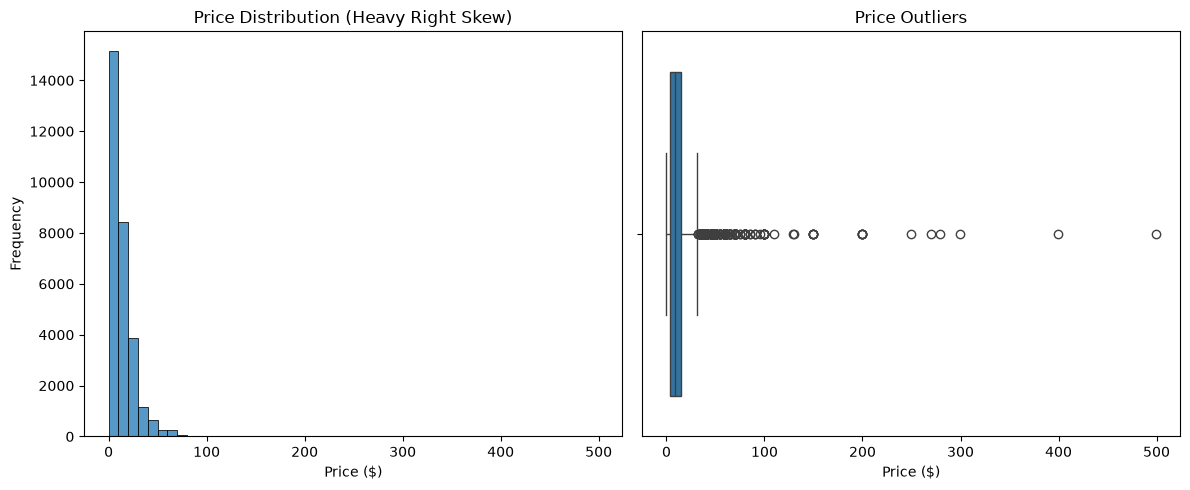

In [9]:
print("--- 1. DATASET ARCHITECTURE & COMPOSITION ---")
print(f"Total records: {len(df)}")
print("\nBreakdown by Application Type:")
print(df['Type'].value_counts())

print("\n--- 2. CARDINALITY & DEDUPLICATION RISKS ---")
unique_appids = df['Appid'].nunique()
unique_names = df['Name'].nunique()
print(f"Unique Appids: {unique_appids} (Potential Duplicates: {len(df) - unique_appids})")
print(f"Unique Names: {unique_names} (Potential Duplicates: {len(df) - unique_names})")
print(f"Unique Developers: {df['Developers'].nunique()}")
print(f"Unique Publishers: {df['Publishers'].nunique()}")

# Calculate unique individual tags
tags_list = df['Tags'].dropna()
tag_set = set()
for tags in tags_list:
    tag_set.update(tags.split(','))
print(f"Standardized Unique Tags: {len(tag_set)}")

print("\n--- 3. DATA QUALITY & MISSING VALUES ---")
missing_counts = df.isnull().sum()
total_rows = len(df)
missing_df = pd.DataFrame({
    'Missing Values': missing_counts, 
    'Percentage (%)': (missing_counts / total_rows) * 100
})
# Filter and sort to show only columns with missing data
print(missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False).round(2))

print("\n--- 4. FEATURE ENGINEERING: PRICE SKEWNESS ---")
# Strip the '$' sign and convert to float
df['price_clean'] = df['price'].astype(str).str.replace('$', '', regex=False).astype(float)

# Calculate statistical skewness (> 1 indicates highly right-skewed)
price_skew = df['price_clean'].skew()
print(f"Price Feature Skewness: {price_skew:.2f}")

# Visualize the right-skewed distribution
plt.figure(figsize=(12, 5))

# Plot 1: Histogram
plt.subplot(1, 2, 1)
sns.histplot(df['price_clean'], bins=50, kde=False)
plt.title("Price Distribution (Heavy Right Skew)")
plt.xlabel("Price ($)")
plt.ylabel("Frequency")

# Plot 2: Boxplot to highlight outliers
plt.subplot(1, 2, 2)
sns.boxplot(x=df['price_clean'])
plt.title("Price Outliers")
plt.xlabel("Price ($)")

plt.tight_layout()
plt.show()

*Nhận định về tập dữ liệu:*

- Phân bố lệch phải mạnh (Heavy Right Skew): Biểu đồ Histogram cho thấy đại đa số các tựa game trên Steam tập trung ở phân khúc giá rất thấp, cụ thể là từ $0 đến dưới $50.   

- Tập trung ở nhóm giá rẻ/miễn phí: Cột tần suất (Frequency) cao nhất nằm ở sát mức $0 (vượt mốc 14.000 game), cho thấy phần lớn thư viện Steam là các game miễn phí (Free to Play) hoặc có giá cực kỳ rẻ.   

- Nhiều giá trị ngoại lệ (Outliers): Biểu đồ Boxplot bên phải thể hiện một lượng lớn các điểm tròn (outliers) trải dài từ mức $100 lên đến $500. Hộp tứ phân vị (box) bị ép rất hẹp về bên trái, chứng tỏ vùng giá trị phổ biến rất hẹp.   

- Khoảng giá cực đoan: Dù phần lớn game có giá trị thấp, vẫn tồn tại những cá thể game được định giá cao bất thường, với các mốc ngoại lệ nổi bật nằm ở khoảng $200, gần $300, $400 và cá biệt lên đến $500.   

### Danh Sách Tags Trong Genres
Xuất ra danh sách các toàn bộ tags game hiện có trong dataset

In [10]:
tags_list = df['Tags'][df['Tags'].notna()]
tag_set = set()

for tags in tags_list:
    tag_list = tags.split(',')
    tag_set.update(tag_list)

print(f'Number of tag recorded: {len(tag_set)}')
print(f'Tag set: {tag_set}')
# Bring the tag set to a file for further purpose
with open('../data/SteamGames_tags.txt', 'w') as r:
    for item in tag_set:
        r.write(f'{item}\n') 

Number of tag recorded: 446
Tag set: {'Jump Scare', 'Experience', 'Mod', 'Local Co-Op', 'Boss Rush', 'Score Attack', 'Fox', 'Moddable', '4X', 'Hockey', 'Nonlinear', 'Naval Combat', 'Level Editor', 'Sexual Content', 'Offroad', 'Football (American)', 'Singleplayer', 'Historical', 'Time Attack', 'Dungeon Crawler', 'Minigames', 'Epic', 'RTS', 'Sandbox', 'Competitive', 'Pinball', 'Survival Horror', 'Electronic Music', 'Roguevania', 'Strategy', 'Cyberpunk', 'Philosophical', 'GameMaker', 'Party Game', 'Spelling', 'Episodic', 'Adventure', 'Precision Platformer', 'Hunting', 'Pixel Graphics', 'Mechs', 'Fishing', 'Basketball', 'Runner', 'Tennis', 'Base Building', 'Cult Classic', 'Heist', 'Turn-Based Strategy', '2D', 'Automobile Sim', 'Replay Value', 'Mahjong', 'Rome', 'Side Scroller', 'Action-Adventure', 'Action RTS', 'Multiplayer', 'Character Action Game', 'Physics', 'Coding', 'Dark Humor', 'Superhero', 'Party-Based RPG', 'Point & Click', 'Difficult', 'Martial Arts', 'Memes', 'Shooter', 'Surreal

*Nhận xét*: Số lượng các tag game là nhiều với khoảng 446 loại khác nhau, điều này thể hiện sự phong phú trong thể loại các game có mặt trên Steam.

### Phân Phối Thời Gian Phát Hành Của Steam Game Theo Năm

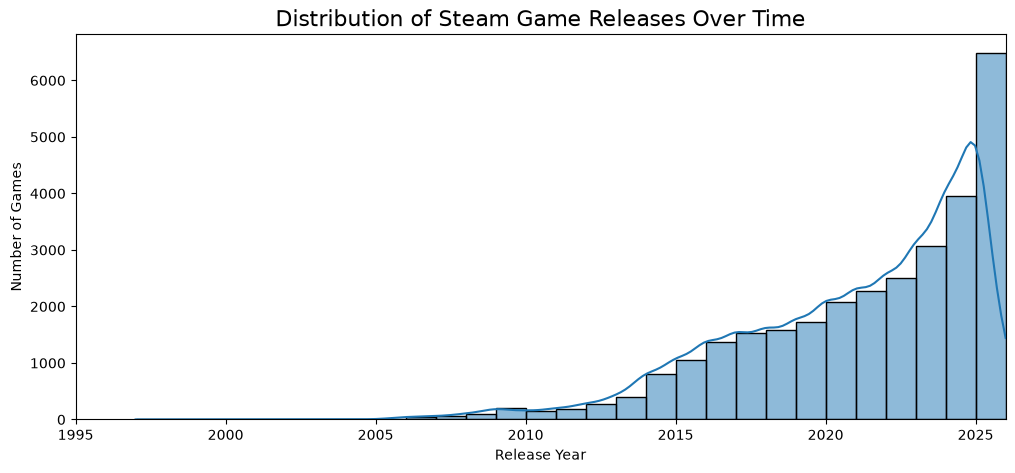

In [11]:
# 2. Game Releases Over Time
# Extract the 4-digit year from the ReleaseDate string
df['ReleaseYear'] = df['ReleaseDate'].astype(str).str.extract(r'(20\d{2}|19\d{2})').astype(float)

plt.figure(figsize=(12, 5))
sns.histplot(df['ReleaseYear'].dropna(), bins=int(df['ReleaseYear'].max() - df['ReleaseYear'].min()), kde=True)
plt.title("Distribution of Steam Game Releases Over Time", fontsize=16)
plt.xlabel("Release Year")
plt.ylabel("Number of Games")
plt.xlim(1995, 2026) # Focus on modern eras
plt.show()

Dựa vào đồ thị cung cấp bên trên, ta có một số nhận định:
- Tăng trưởng bùng nổ (Exponential Growth): Số lượng game phát hành trên Steam thể hiện xu hướng tăng trưởng mạnh mẽ và liên tục theo thời gian.   

- Giai đoạn đầu(1995 - 2010): Số lượng tựa game ra mắt mỗi năm trong giai đoạn này rất thấp, biểu đồ đi ngang và gần như bám sát trục hoành.   

- Giai đoạn tăng tốc(Sau 2014): Biểu đồ bắt đầu dốc lên rõ rệt từ khoảng năm 2014-2015, đánh dấu thời kỳ mở rộng mạnh mẽ của nền tảng Steam.   

- Đạt đỉnh cao kỷ lục: Số lượng game phát hành đạt đỉnh ở cột dữ liệu cuối cùng (khoảng mốc 2025-2026), vọt lên mức cao nhất với hơn 6.000 tựa game. Điều này cho thấy số lượng sản phẩm tung ra thị trường đang ở mức cao chưa từng có.   